In [192]:
%pylab inline
import os
from astropy.table import Table, vstack
import astropy.io.fits as pyfits

import matplotlib
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

from astropy.visualization import make_lupton_rgb


from lsst.daf.persistence import Butler
butler18 = Butler('./homeDir/data/hsc_ssp/dr3/s19a/data/s19a_wide/')
skymap  =    butler18.get('deepCoadd_skyMap')

import lsst.afw.table as afwTable
import lsst.afw.image as afwImage
import lsst.afw.display as afwDisplay
#import lsst.afw.geom as afwGeom
import lsst.geom as afwGeom
from lsst.meas.base.noiseReplacer import NoiseReplacerConfig,NoiseReplacer
import lsst.analysis.deblender as deblender

import astropy.io.ascii as ascii
afwDisplay.setDefaultBackend('matplotlib')
plt.rcParams['figure.figsize'] = (15, 15)

def findInAperture(centList,radius,cat):
    """Return the objects within Aperture"""
    oneObjCatalog = afwTable.SourceCatalog(cat.getSchema())
    centroidName = cat.table.getCentroidDefinition()
    oneObjCatalog.table.defineCentroid(centroidName)

    for cent in centList:
        x, y = cent.getX(), cent.getY()
        s = oneObjCatalog.addNew()
        s.set("%s_x" % centroidName, x)
        s.set("%s_y" % centroidName, y)

    return afwTable.matchXy(cat, oneObjCatalog, radius)


Populating the interactive namespace from numpy and matplotlib


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/IPython/core/magics/pylab.py:160: UserWarning: pylab import has clobbered these variables: ['table', 'exp', 'vstack']
`%matplotlib` prevents importing * from pylab and numpy
  "\n`%matplotlib` prevents importing * from pylab and numpy"
Config override file '?' appears to use 'root' instead of 'config'; trying with 'root'


# ICG

In [5]:
# Preparing data
catNei=Table.read('./wrkDir/database/compare/ICG-neighbour-SDSS-undetect.csv')
catCen=Table.read('./wrkDir/database/compare/ICG_MW-central-202004222012.csv')
if False:
    cids=np.unique(catNei['central_id'])
    catCen=catCen[cids-1]
    catCen['central_id']=cids
    catCen.write('./wrkDir/database/compare/ICG_MW-central-20200316.csv')

if False:
    catCen['tract']=None
    catCen['patch']=None
    for ss in catCen:
        centCoord=afwGeom.SpherePoint(afwGeom.Angle(ss['ra'],afwGeom.degrees),afwGeom.Angle(ss['dec'],afwGeom.degrees))
        TPinfo=skymap.findClosestTractPatchList([centCoord])[0]
        ss['tract']=TPinfo[0].getId()
        ss['patch']='%d,%d' %TPinfo[1][0].getIndex()
    catCen.write('./wrkdir/database/compare/icg_mw-central-20200316.csv')

if False:
    from astropy.cosmology import FlatLambdaCDM
    cosmo = FlatLambdaCDM(H0=67.3, Om0=0.315, Tcmb0=2.725)
    DD=cosmo.luminosity_distance(catCen['z']).value/(1.+catCen['z'])**2*1000.
    rPix20kpc=20/DD/np.pi*180.*3600./0.168
    catCen['rPix20kpc']=rPix20kpc
    catCen.write('./wrkDir/database/compare/ICG_MW-central-202004222012.csv')


In [158]:
msk1=(catCen['ra']>214.236)&(catCen['ra']<214.237)
print(catCen[msk1])
msk2=(catCen['ra']>189.256)&(catCen['ra']<189.257)
print(catCen[msk2])
msk3=(catCen['ra']>175.392)&(catCen['ra']<175.393)
print(catCen[msk3])
rlist=np.int_(np.array([171,265,1703])*0.2/0.168)+1
print(rlist)
idlist=[322,1000,16]
msklist=[msk1,msk2,msk3]

   ra      dec      z       log_M   ... central_id tract patch     rPix20kpc    
-------- ------- -------- --------- ... ---------- ----- ----- -----------------
214.2369 -0.7823 0.125555 10.777541 ...        342  9371   7,4 50.95943085172383
   ra     dec      z       log_M   ... central_id tract patch     rPix20kpc    
-------- ------ -------- --------- ... ---------- ----- ----- -----------------
189.2565 0.9171 0.076498 10.788947 ...       1088  9597   6,5 79.01938324613808
   ra      dec      z       log_M   ... central_id tract patch     rPix20kpc    
-------- ------- -------- --------- ... ---------- ----- ----- -----------------
175.3923 -1.2026 0.077633 10.839533 ...         18  9344   1,2 77.96805338893223
[ 204  316 2028]


In [212]:
ishow=0
ssCen=catCen[msklist[ishow]][0]
dataId = {'filter': 'HSC-G', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
srcG=butler18.get('deepCoadd_forced_src',**dataId)
expG = butler18.get('deepCoadd_calexp', **dataId)
dataId = {'filter': 'HSC-R', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
srcR=butler18.get('deepCoadd_forced_src',**dataId)
expR = butler18.get('deepCoadd_calexp', **dataId)
dataId = {'filter': 'HSC-I', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
srcI=butler18.get('deepCoadd_forced_src',**dataId)
expI = butler18.get('deepCoadd_calexp', **dataId)
dataId = {'filter': 'HSC-Z', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
srcZ=butler18.get('deepCoadd_forced_src',**dataId)
expZ = butler18.get('deepCoadd_calexp', **dataId)
dataId = {'filter': 'HSC-Y', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
srcY=butler18.get('deepCoadd_forced_src',**dataId)
expY = butler18.get('deepCoadd_calexp', **dataId)

In [213]:
explist=[expG,expR,expI,expZ,expY]
bandnames=['HSC-G','HSC-R','HSC-I','HSC-Z','HSC-Y']
showR=rlist[ishow]/2
catUnMat=catNei[catNei['central_id']==ssCen['central_id']]

In [209]:
#Show all Galaxies

centCoord=afwGeom.SpherePoint(afwGeom.Angle(ssCen['ra'],afwGeom.degrees),afwGeom.Angle(ssCen['dec'],afwGeom.degrees))
wcs=expG.getWcs()
centPoint=afwGeom.Point2I(wcs.skyToPixel(centCoord))

extU=afwGeom.Extent2I(showR,showR)
boxU=afwGeom.Box2I(centPoint-extU,2*extU)
boxU.clip(expG.getBBox())
expShow=expG[boxU]
display1 = afwDisplay.getDisplay(frame=13)
display1.setMaskTransparency(100)
#display1.scale("Asinh", "zscale")
display1.scale("asinh", "zscale")
display1.mtv(expShow,title='ICG %d pix' %(showR))

nameNchild = "deblend_nChild"
matched=findInAperture([centPoint],showR*1.4,src18)

with display1.Buffering():
    display1.dot('o',centPoint.getX(),centPoint.getY(), size=ssCen['rPix20kpc'], ctype=afwDisplay.BLUE) 
    for mm in matched:
        ssShow=mm[0]
        if ssShow[nameNchild]==0:
            label='+'
            display1.dot(label,ssShow.getX(),ssShow.getY(), size=4, ctype=afwDisplay.GREEN) 
    for ssShow in catUnMat:
        raShow=ssShow['satellite_ra']
        decShow=ssShow['satellite_dec']
        cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
        pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
        #print(pShow-centPoint)
        label='o'
        display1.dot(label,pShow.getX(),pShow.getY(), size=4, ctype=afwDisplay.RED) 

display1.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d.png' %(ssCen['central_id']))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:32: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:32: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)


214.237649
214.237991
214.237367
214.236674
214.238539
214.235036
214.23559
214.238274
214.235609
214.238986
214.237314
214.253009
214.240804
214.251258
214.228975


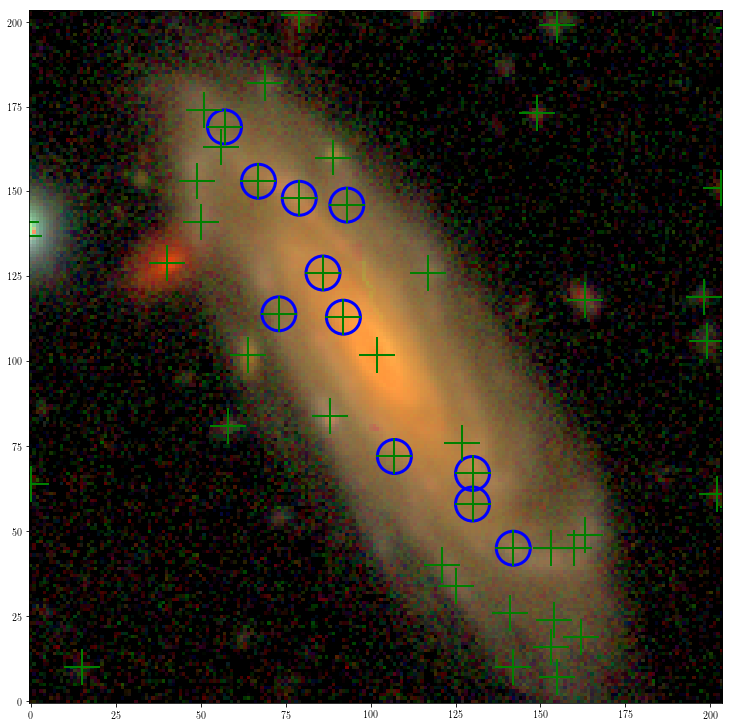

In [217]:
outDir='wrkDir/exfaGalAll/plot-brightObj/outcome/'
symbolR=5
centCoord=afwGeom.SpherePoint(afwGeom.Angle(ssCen['ra'],afwGeom.degrees),afwGeom.Angle(ssCen['dec'],afwGeom.degrees))
wcs=expG.getWcs()
centPoint=afwGeom.Point2I(wcs.skyToPixel(centCoord))

extU=afwGeom.Extent2I(showR,showR)
boxU=afwGeom.Box2I(centPoint-extU,2*extU)
boxU.clip(expG.getBBox())
imglist=[]
for i,exp in enumerate(explist):
    dataImg=exp[boxU].getImage().getArray()[:,:]
    imglist.append(dataImg)
    pyfits.writeto(os.path.join(outDir,'img-%s-%s.fits' %(idlist[ishow],bandnames[i])),dataImg,overwrite=True)

fig=plt.figure(figsize=(showR/8,showR/8))
ax=fig.add_subplot(1,1,1)
imgShow=make_lupton_rgb(imglist[2],imglist[1],imglist[0],stretch=0.5,Q=10)
ax.imshow(imgShow,origin='lower left')
nameNchild = "deblend_nChild"
matched=findInAperture([centPoint],showR*1.4,srcR)

xcol=[];ycol=[]
for mm in matched:
    ssShow=mm[0]
    if not ssShow[nameNchild]==0:
        continue
    pShow=afwGeom.Point2I(ssShow.getCentroid()) 
    dis=pShow-centPoint+extU
    xcol.append(dis.getX());ycol.append(dis.getY())
    x, y = np.array([[-symbolR, symbolR], [0,0]])
    line = mlines.Line2D(dis.getX() + x, dis.getY() + y, lw=2.,color='green')
    ax.add_line(line)
    x, y = np.array([[0, 0], [-symbolR,symbolR]])
    line = mlines.Line2D(dis.getX() + x, dis.getY() + y, lw=2.,color='green')
    ax.add_line(line)
table=Table(data=[xcol,ycol],names=['x','y'])
table.write(os.path.join(outDir,'HSC-detection-%s.csv' %idlist[ishow]))

xcol=[];ycol=[]
for ss in catUnMat:
    raShow=ss['satellite_ra']
    print(raShow)
    decShow=ss['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    dis=pShow-centPoint+extU
    xcol.append(dis.getX());ycol.append(dis.getY())
    mcir =   mpatches.Circle((dis.getX(),dis.getY()),radius=symbolR,ls='-',facecolor='None',edgecolor='blue',lw=3.)
    ax.add_patch(mcir)
table=Table(data=[xcol,ycol],names=['x','y'])
table.write(os.path.join(outDir,'SDSS-undetect-%s.csv' %idlist[ishow]))
plt.savefig(os.path.join(outDir,'img-%s-rgb.pdf' %(idlist[ishow])))


In [ ]:
# Show Interested Galaxies
#fp18  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
#              for measRecord in src18}
#noiConfig   =   NoiseReplacerConfig()
#nrper18=  NoiseReplacer(noiConfig, expG, fp18)

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

2
(25268, 21397)
0
1
(25343, 21323)
1
(25266, 21357)
2
(25756, 21325)


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

1
(25678, 21426)
2
(26890, 21662)
2
(26890, 21662)
1
(26882, 21669)
2
(26916, 21668)
1
(26925, 21712)
1
(26697, 21720)
2
(26877, 22057)


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

1
(26821, 22057)
1
(25519, 22434)
1
(25484, 22427)


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:30: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)


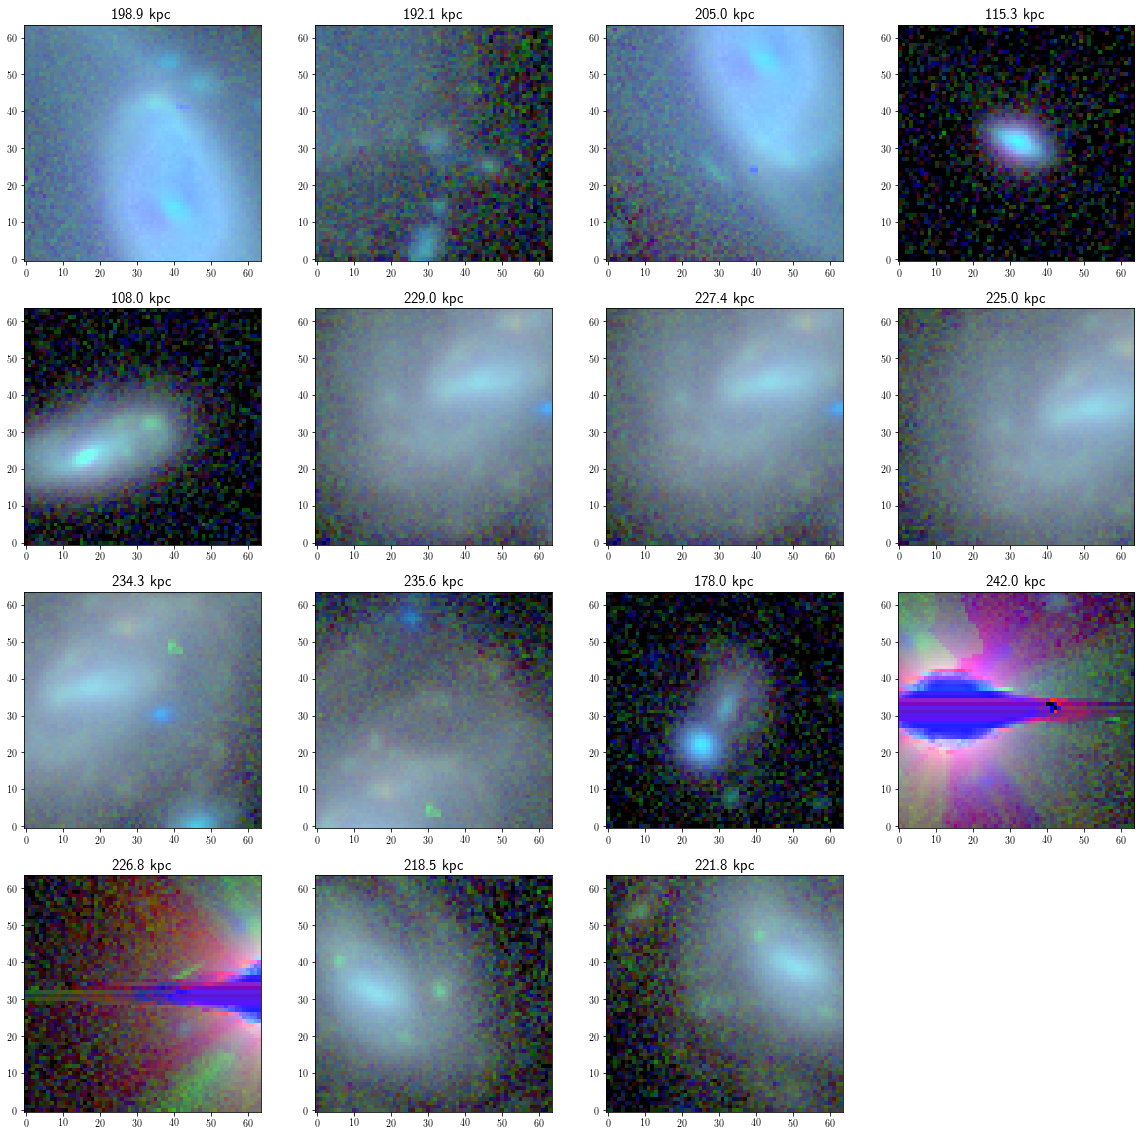

In [73]:
dis=np.sqrt((catUnMat['satellite_ra']-catUnMat['central_ra'])**2.+(catUnMat['satellite_dec']-catUnMat['central_dec'])**2.)*3600./0.168
msk=dis>ssCen['rPix20kpc']
catsU=catUnMat[msk]
disU=dis[msk]
ndata=len(catsU)
nplotS=int(np.sqrt(ndata))
nplot=nplotS**2

fig =   plt.figure(figsize=(5*nplotS, 5*nplotS))

iss=1
for i in range(nplot):
    ssShow=catsU[i]
    disShow=disU[i]
    imglist=[]
    raShow=ssShow['satellite_ra']
    decShow=ssShow['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    matched=findInAperture([pShow],10,src18)
    print(len(matched))
    for mm in matched[0:1]:
        ss=mm[0]
        if ss[nameNchild]==0:
            cc=afwGeom.Point2I(ss.getCentroid())
            print(cc)
            extU=afwGeom.Extent2I(32,32)
            boxU=afwGeom.Box2I(cc-extU,2*extU)

            for exp in explist:
                boxU.clip(exp.getBBox())
                #nrper18.insertSource(ss.getId())
                imglist.append(exp.getImage()[boxU].getArray()[:,:])
                #nrper18.removeSource(ss.getId())
            imgShow=make_lupton_rgb(imglist[0],imglist[1],imglist[2],stretch=0.5)
            ax  =   fig.add_subplot(nplotS,nplotS,iss)
            iss+=1
            ax.imshow(imgShow,origin='lower left')
            ax.set_title('%.1f kpc' %(disShow/ssCen['rPix20kpc']*20),fontsize=15)

#display2.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d-unMat.png' %(ssCen['central_id']))

In [32]:
catUnMat

central_id,central_ra,central_dec,central_redshift,satellite_ra,satellite_dec,satellite_r-band_cModel_mag,satellite_g-band_cModel_mag
int64,float64,float64,float64,float64,float64,float64,float64
1088,189.2565,0.9171,0.076498,189.290195,0.902641,17.98672867,18.51271629
1088,189.2565,0.9171,0.076498,189.289819,0.902202,19.24434662,19.88788223
1088,189.2565,0.9171,0.076498,189.28688,0.898897,20.91396713,22.12686157
1088,189.2565,0.9171,0.076498,189.290517,0.900604,18.6774559,19.32341194
1088,189.2565,0.9171,0.076498,189.267597,0.898971,20.31694031,21.62313652
1088,189.2565,0.9171,0.076498,189.271237,0.903703,20.71231461,21.14812469
1088,189.2565,0.9171,0.076498,189.254871,0.915389,20.53342438,21.07132339
1088,189.2565,0.9171,0.076498,189.214355,0.914693,19.29010773,19.72637558
1088,189.2565,0.9171,0.076498,189.214644,0.914804,19.27373314,19.67025185


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

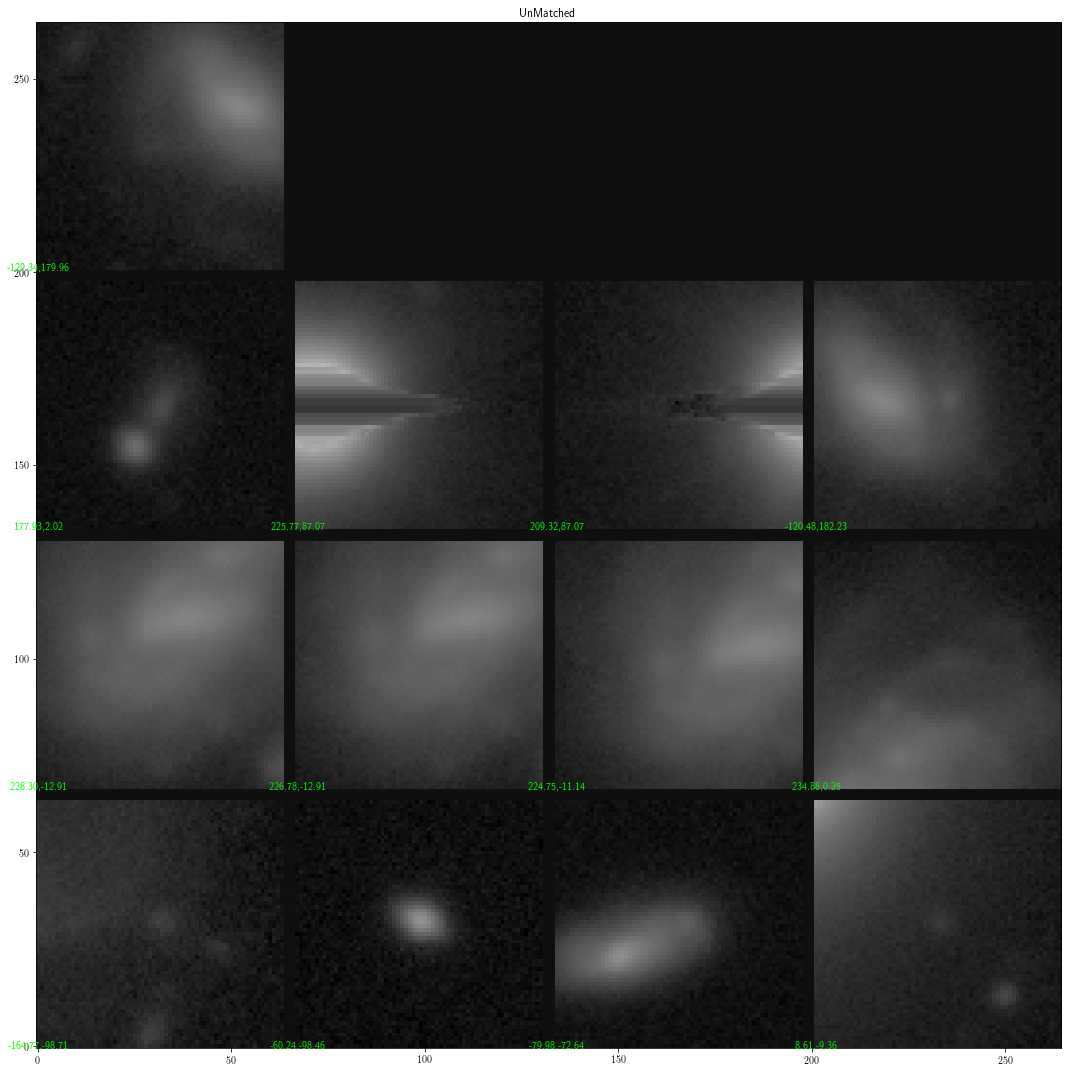

In [15]:
# Show Interested Galaxies
mos=afwDisplay.utils.Mosaic()
noiConfig   =   NoiseReplacerConfig()
fp18  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
              for measRecord in src18}
#nrper18=  NoiseReplacer(noiConfig, expG, fp18)

display2 = afwDisplay.getDisplay(frame=3)
display2.setMaskTransparency(90)
#display2.scale("Asinh", "zscale")
display2.scale("asinh", "zscale")
ratio=20./ssCen['rPix20kpc']
for ssShow in catUnMat:
    raShow=ssShow['satellite_ra']
    decShow=ssShow['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    matched=findInAperture([pShow],4,src18)
    for mm in matched:
        ss=mm[0]
        if ss[nameNchild]==0:
            cc=afwGeom.Point2I(ss.getCentroid())
            dis=cc-centPoint
            label='%.2f,%.2f' %(dis.getX()*ratio,dis.getY()*ratio)
            boxU.clip(expG.getBBox())
            extU=afwGeom.Extent2I(32,32)
            boxU=afwGeom.Box2I(cc-extU,2*extU)
            #nrper18.insertSource(ss.getId())
            imgShow=afwImage.MaskedImageF(boxU)
            imgShow.getImage().getArray()[:,:]=expG.getImage()[boxU].getArray()[:,:]
            mos.append(imgShow,label=label)
            del imgShow
            #nrper18.removeSource(ss.getId())

mos.makeMosaic(display=display2,title='UnMatched')
display2.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d-unMat.png' %(ssCen['central_id']))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

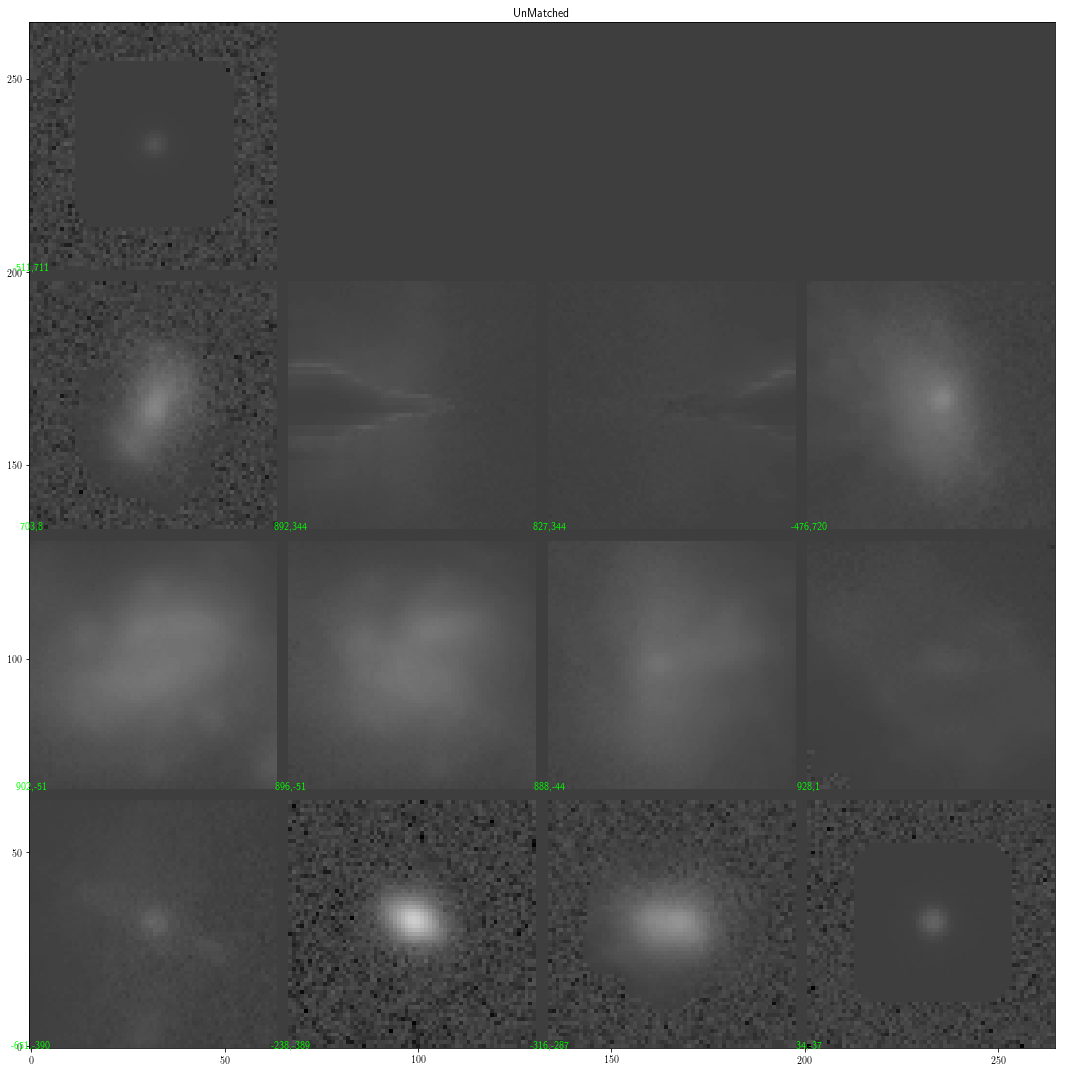

In [16]:
# Show Interested Galaxies
mos=afwDisplay.utils.Mosaic()
noiConfig   =   NoiseReplacerConfig()
fp18  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
              for measRecord in src18}
nrper18=  NoiseReplacer(noiConfig, expG, fp18)

display3 = afwDisplay.getDisplay(frame=4)
display3.setMaskTransparency(90)
#display3.scale("Asinh", "zscale")
display3.scale("asinh", "zscale")

for ssShow in catUnMat:
    raShow=ssShow['satellite_ra']
    decShow=ssShow['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    matched=findInAperture([pShow],4,src18)
    for mm in matched:
        ss=mm[0]
        if ss[nameNchild]==0:
            cc=afwGeom.Point2I(ss.getCentroid())
            dis=cc-centPoint
            label='%d,%d' %(dis.getX(),dis.getY())
            boxU.clip(expG.getBBox())
            extU=afwGeom.Extent2I(32,32)
            boxU=afwGeom.Box2I(cc-extU,2*extU)
            nrper18.insertSource(ss.getId())
            imgShow=afwImage.MaskedImageF(boxU)
            imgShow.getImage().getArray()[:,:]=expG.getImage()[boxU].getArray()[:,:]
            mos.append(imgShow,label=label)
            del imgShow
            nrper18.removeSource(ss.getId())

mos.makeMosaic(display=display3,title='UnMatched')
display3.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d-unMat-deblend.png' %(ssCen['central_id']))